<a href="https://colab.research.google.com/github/amrbensalah4-debug/ETRS923_IA/blob/main/TP1_MNIST/TP1_MNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
projet = '/content/drive/MyDrive/ETRS923/TP1_MNIST'
os.makedirs(projet + '/models', exist_ok=True)
os.chdir(projet)
print("Dossier de travail :", os.getcwd())

Mounted at /content/drive
Dossier de travail : /content/drive/MyDrive/ETRS923/TP1_MNIST


## Préparation : chargement de MNIST

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Images d'entraînement : (60000, 28, 28)
Images de test        : (10000, 28, 28)


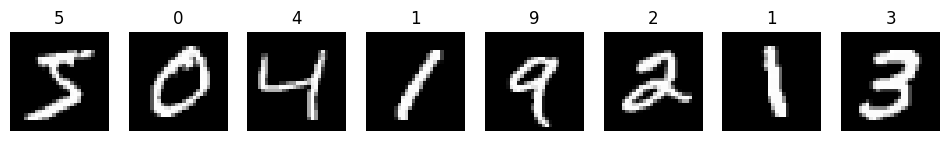

In [3]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt

# Charger MNIST (téléchargé automatiquement)
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print("Images d'entraînement :", x_train.shape)
print("Images de test        :", x_test.shape)

# Afficher quelques exemples
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for i, ax in enumerate(axes):
    ax.imshow(x_train[i], cmap='gray')
    ax.set_title(y_train[i])
    ax.axis('off')
plt.show()

# Partie 1 : Choix de la fonction d'activation

Conditions imposées par le sujet :
- Optimiseur : **adam**
- Fonction coût : **categorical_crossentropy**

On compare plusieurs réseaux (softmax, ReLU, tanh, sigmoid) selon :
l'accuracy, le nombre d'epochs et le nombre de poids (synapses).

## Préparation des données (commune à toutes les questions)

Le réseau dense (MLP) ne lit pas une image en carré, il lit une ligne de nombres.
Il faut donc :
1. **Aplatir** chaque image 28×28 en un vecteur de 784 pixels.
2. **Normaliser** les pixels de [0, 255] vers [0, 1] : le réseau apprend mieux avec de petites valeurs.
3. **Encoder les réponses en one-hot** : le chiffre 5 devient [0,0,0,0,0,1,0,0,0,0].
   C'est le format attendu par categorical_crossentropy.

In [4]:
# ============================================================
# PRÉPARATION DES DONNÉES
# ============================================================

# --- 1. Aplatir les images : 28x28 -> 784 ---
# reshape(-1, 784) : "-1" laisse Python calculer le nombre d'images tout seul
# Résultat : un tableau de 60000 lignes (images) x 784 colonnes (pixels)
x_train_flat = x_train.reshape(-1, 784)
x_test_flat  = x_test.reshape(-1, 784)

# --- 2. Normaliser les pixels entre 0 et 1 ---
# Les pixels vont de 0 (noir) à 255 (blanc)
# astype('float32') : convertit en nombres à virgule (sinon la division ne marche pas bien)
# / 255 : ramène toutes les valeurs entre 0 et 1
x_train_flat = x_train_flat.astype('float32') / 255
x_test_flat  = x_test_flat.astype('float32') / 255

# --- 3. Encoder les réponses en one-hot ---
# Exigé par la fonction coût categorical_crossentropy
# Exemple : 5 -> [0,0,0,0,0,1,0,0,0,0]
y_train_cat = keras.utils.to_categorical(y_train, 10)
y_test_cat  = keras.utils.to_categorical(y_test, 10)

# --- Vérifications ---
print("Forme des images d'entraînement :", x_train_flat.shape)   # attendu : (60000, 784)
print("Valeur max d'un pixel :", x_train_flat.max())             # attendu : 1.0
print("Réponse de la 1re image :", y_train[0], "->", y_train_cat[0])

# --- Tableau des résultats (rempli à chaque question, utilisé en 1.e) ---
resultats = []

Forme des images d'entraînement : (60000, 784)
Valeur max d'un pixel : 1.0
Réponse de la 1re image : 5 -> [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


## Question 1.a : Réseau à deux couches avec softmax

Architecture : 784 (entrée) → 10 neurones (sortie, softmax)

- Aucune couche cachée : chaque neurone de sortie fait une somme pondérée des 784 pixels.
- **softmax** transforme les 10 sorties en probabilités dont la somme vaut 100 %.
- Le chiffre prédit est celui qui a la plus grande probabilité.

Nombre de poids attendu : 784 × 10 + 10 (biais) = **7 850**

In [5]:
# ============================================================
# QUESTION 1.a : Réseau softmax (784 -> 10)
# ============================================================

# --- 1. CONSTRUIRE le réseau ---
# Sequential : les couches s'enchaînent l'une après l'autre
model_softmax = keras.Sequential([
    keras.Input(shape=(784,)),                  # entrée : 784 pixels
    keras.layers.Dense(10, activation='softmax')  # sortie : 10 neurones (un par chiffre)
])
# "Dense" = chaque neurone est relié aux 784 pixels (couche entièrement connectée)

model_softmax.summary()   # affiche l'architecture et le nombre de poids

# --- 2. COMPILER : choisir comment le réseau apprend ---
model_softmax.compile(
    optimizer='adam',                     # méthode de correction des poids (imposée)
    loss='categorical_crossentropy',      # mesure de l'erreur (imposée, labels one-hot)
    metrics=['accuracy']                  # on veut suivre le % de bonnes réponses
)

# --- 3. ENTRAÎNER ---
historique_softmax = model_softmax.fit(
    x_train_flat, y_train_cat,
    epochs=10,              # 10 passages complets sur les 60 000 images
    batch_size=128,         # correction des poids tous les 128 images
    validation_split=0.1    # 10 % des images mises de côté pour surveiller l'apprentissage
)

# --- 4. TESTER sur les 10 000 images jamais vues ---
perte, precision = model_softmax.evaluate(x_test_flat, y_test_cat, verbose=0)
print(f"\nAccuracy sur le test : {precision*100:.2f} %")

# --- Enregistrer le résultat dans le tableau ---
resultats.append({
    'Question': '1.a',
    'Architecture': '784 → 10',
    'Activation': 'softmax',
    'Epochs': 10,
    'Nb de poids': model_softmax.count_params(),
    'Accuracy test (%)': round(precision*100, 2)
})

# --- Sauvegarder le modèle dans le Drive (utile pour le TP3) ---
model_softmax.save('models/mnist_softmax.keras')
print("Modèle sauvegardé dans models/")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8196 - loss: 0.7274 - val_accuracy: 0.9117 - val_loss: 0.3539
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8979 - loss: 0.3801 - val_accuracy: 0.9253 - val_loss: 0.2872
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9087 - loss: 0.3327 - val_accuracy: 0.9298 - val_loss: 0.2622
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9140 - loss: 0.3107 - val_accuracy: 0.9323 - val_loss: 0.2504
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9168 - loss: 0.2978 - val_accuracy: 0.9360 - val_loss: 0.2434
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9183 - loss: 0.2888 - val_accuracy: 0.9362 - val_loss: 0.2381
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9216 - loss: 0.2821 - val_accuracy: 0.9365 - val_loss: 0.2335
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9224 - loss: 0.2771 - val_accuracy: 0.

## Question 1.b : Réseau avec 2 couches cachées ReLU

Architecture : 784 → 128 (ReLU) → 64 (ReLU) → 10 (softmax)

- Les **couches cachées** permettent au réseau d'apprendre par étapes :
  petits motifs (traits, courbes), puis formes, puis chiffre.
- **ReLU** : si le score d'un neurone est négatif → 0, sinon on le garde.
  Cette non-linéarité est indispensable : sans elle, plusieurs couches
  équivaudraient à une seule.
- La sortie reste en **softmax** pour obtenir 10 probabilités.

Nombre de poids attendu : 100 480 + 8 256 + 650 = **109 386**

In [6]:
# ============================================================
# QUESTION 1.b : 2 couches cachées ReLU (784 -> 128 -> 64 -> 10)
# ============================================================

# --- 1. CONSTRUIRE le réseau ---
model_relu = keras.Sequential([
    keras.Input(shape=(784,)),                      # entrée : 784 pixels
    keras.layers.Dense(128, activation='relu'),     # 1re couche cachée : 128 neurones
    keras.layers.Dense(64,  activation='relu'),     # 2e couche cachée : 64 neurones
    keras.layers.Dense(10,  activation='softmax')   # sortie : 10 probabilités
])

model_relu.summary()   # vérifier : 109 386 paramètres

# --- 2. COMPILER (mêmes réglages qu'en 1.a, imposés par le sujet) ---
model_relu.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# --- 3. ENTRAÎNER (mêmes epochs et batch qu'en 1.a pour une comparaison juste) ---
historique_relu = model_relu.fit(
    x_train_flat, y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.1
)

# --- 4. TESTER sur les 10 000 images jamais vues ---
perte, precision = model_relu.evaluate(x_test_flat, y_test_cat, verbose=0)
print(f"\nAccuracy sur le test : {precision*100:.2f} %")

# --- Enregistrer le résultat dans le tableau ---
resultats.append({
    'Question': '1.b',
    'Architecture': '784 → 128 → 64 → 10',
    'Activation': 'ReLU',
    'Epochs': 10,
    'Nb de poids': model_relu.count_params(),
    'Accuracy test (%)': round(precision*100, 2)
})

# --- Sauvegarder le modèle dans le Drive ---
model_relu.save('models/mnist_relu.keras')
print("Modèle sauvegardé dans models/")

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9004 - loss: 0.3506 - val_accuracy: 0.9622 - val_loss: 0.1411
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9596 - loss: 0.1392 - val_accuracy: 0.9697 - val_loss: 0.1017
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9712 - loss: 0.0971 - val_accuracy: 0.9752 - val_loss: 0.0860
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9775 - loss: 0.0741 - val_accuracy: 0.9753 - val_loss: 0.0820
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9826 - loss: 0.0572 - val_accuracy: 0.9767 - val_loss: 0.0768
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9851 - loss: 0.0467 - val_accuracy: 0.9780 - val_loss: 0.0790
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9883 - loss: 0.0384 - val_accuracy: 0.9777 - val_loss: 0.0783
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9899 - loss: 0.0319 - val_accuracy: 0.